In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [58]:
df = pd.read_csv('C:\\Users\\aishu\\OneDrive\\Desktop\\Techsara\\Assignment 2\\housing.csv')

In [59]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [60]:
df.shape

(20640, 10)

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [62]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [63]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [64]:
X= df.drop('median_house_value', axis=1)
y= df['median_house_value']

In [65]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, Y_train.shape, y_test.shape


((16512, 9), (4128, 9), (16512,), (4128,))

In [66]:
numeric_columns = X_train.select_dtypes(include='number').columns
text_columns = ['ocean_proximity']

In [67]:
numeric_steps = Pipeline([
    ('fill_missing', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

In [68]:
text_steps = OneHotEncoder(drop=['INLAND'], handle_unknown='ignore')


In [69]:
preparation = ColumnTransformer([
    ('numbers', numeric_steps, numeric_columns),
    ('text', text_steps, text_columns)
])

## Linear Regression 

In [70]:
linear_model = Pipeline([
    ('prepare', preparation),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)
print('Linear Regression is trained.')

Linear Regression is trained.


## Tune and Train Ridge

In [71]:
validation = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_pipeline = Pipeline([
    ('prepare', preparation),
    ('model', Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={'model__alpha': np.logspace(-3, 5, 25)},
    scoring='neg_root_mean_squared_error',
    cv=validation
)

ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_

print('Best Ridge alpha:', ridge_search.best_params_['model__alpha'])
print('Validation RMSE:', round(-ridge_search.best_score_, 2))

Best Ridge alpha: 1.0
Validation RMSE: 68595.8


## Tune and train Lasso

In [72]:
lasso_pipeline = Pipeline([
    ('prepare', preparation),
    ('model', Lasso(max_iter=100000, tol=0.00001))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={'model__alpha': np.logspace(-2, 4, 25)},
    scoring='neg_root_mean_squared_error',
    cv=validation
)

lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_

print('Best Lasso alpha:', lasso_search.best_params_['model__alpha'])
print('Validation RMSE:', round(-lasso_search.best_score_, 2))

Best Lasso alpha: 10.0
Validation RMSE: 68599.98


## Predict and compare the test results

In [73]:
models = {
    'Linear': linear_model,
    'Ridge': ridge_model,
    'Lasso': lasso_model
}

scores = []

for name, model in models.items():
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    scores.append([name, mae, mse, rmse, r2])

results = pd.DataFrame(scores, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])
results = results.set_index('Model').sort_values('RMSE')

display(results.round(4))

,MAE,MSE,RMSE,R2
Model,,,,
Linear,50670.4892,4.908291e+09,70059.1933,0.6254
Ridge,50682.4064,4.910083e+09,70071.9877,0.6253
Lasso,50684.0755,4.910311e+09,70073.6118,0.6253


## Compare the coefficients

In [74]:
feature_names = linear_model.named_steps['prepare'].get_feature_names_out()

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Linear': linear_model.named_steps['model'].coef_,
    'Ridge': ridge_model.named_steps['model'].coef_,
    'Lasso': lasso_model.named_steps['model'].coef_
})

display(coefficients.round(2))

zero_count = (coefficients['Lasso'].abs() < 0.00000001).sum()
print('Number of coefficients Lasso made zero:', zero_count)

,Feature,Linear,Ridge,Lasso
0,numbers__longitude,-53826.65,-53933.80,-54006.79
1,numbers__latitude,-54415.70,-54544.70,-54628.54
2,numbers__housing_median_age,13889.87,13902.76,13911.49
3,numbers__total_rooms,-13094.25,-13072.53,-12927.78
4,numbers__total_bedrooms,43068.18,43085.04,43013.93
5,numbers__population,-43403.43,-43400.11,-43349.91
6,numbers__households,18382.20,18340.28,18224.43
7,numbers__median_income,75167.77,75159.41,75132.94
8,text__ocean_proximity_<1H OCEAN,39786.66,39651.66,39529.56
9,text__ocean_proximity_ISLAND,175911.73,140567.81,134282.98


Number of coefficients Lasso made zero: 0


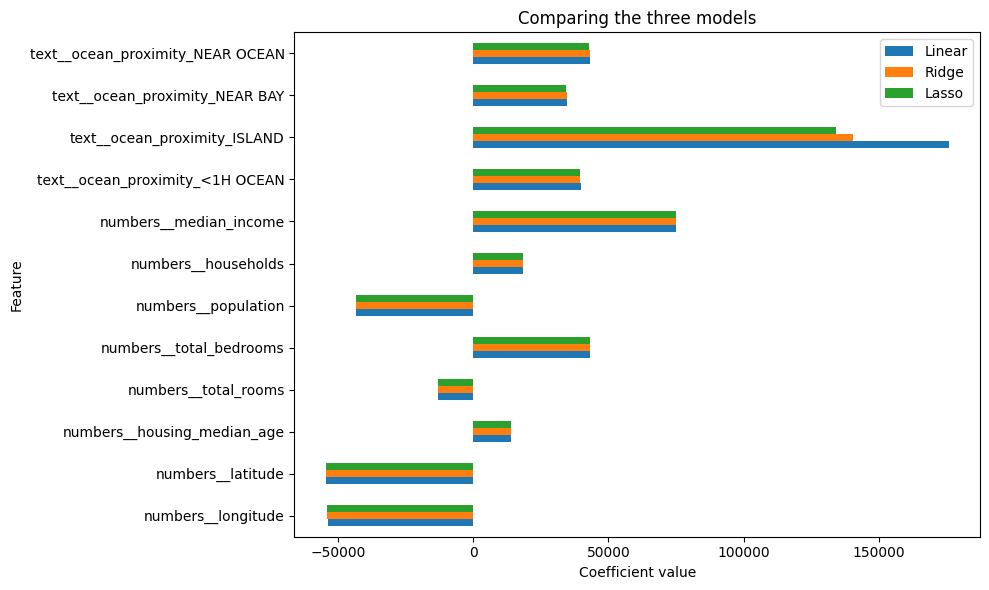

In [75]:
coefficients.set_index('Feature').plot(kind='barh', figsize=(10, 6))
plt.title('Comparing the three models')
plt.xlabel('Coefficient value')
plt.tight_layout()
plt.show()

## Conclusion

In [76]:
best_model = results.index[0]
best_rmse = results.iloc[0]['RMSE']
best_r2 = results.iloc[0]['R2']
gap = results.iloc[1]['RMSE'] - best_rmse

print(
    f'{best_model} performed best on this test split, with the lowest RMSE '
    f'(${best_rmse:,.2f}) and an R² of {best_r2:.4f}. '
    f'Its RMSE was only ${gap:,.2f} lower than the next model, so the advantage is small '
    f'and another split could give a different winner. '
    f'Regularization reduced the overall size of the coefficients but did not improve '
    f'test RMSE here, and the tuned Lasso model made {zero_count} coefficients zero.'
)

Linear performed best on this test split, with the lowest RMSE ($70,059.19) and an R² of 0.6254. Its RMSE was only $12.79 lower than the next model, so the advantage is small and another split could give a different winner. Regularization reduced the overall size of the coefficients but did not improve test RMSE here, and the tuned Lasso model made 0 coefficients zero.
